# 03 - Costs and Parameter Sweep

Prototype a cost-aware backtest and sweep a tiny parameter grid to see how costs impact the rolling z-score strategy.

In [17]:
from pathlib import Path
import sys

NOTEBOOK_DIR = Path().resolve()
CANDIDATES = [NOTEBOOK_DIR, NOTEBOOK_DIR.parent, NOTEBOOK_DIR.parent.parent]
PROJECT_ROOT = None
for candidate in CANDIDATES:
    if (candidate / 'src' / '__init__.py').exists():
        PROJECT_ROOT = candidate
        break

if PROJECT_ROOT is None:
    raise RuntimeError('Unable to locate project root containing src/__init__.py')

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.preprocess import chronological_train_test_split
from src.param_search import grid_search
from src.metrics import sharpe_ratio, max_drawdown, trade_count, sharpe_confidence_interval, buy_and_hold_metrics

plt.style.use('seaborn-v0_8')

## Load processed data

In [18]:
DATA_PATH = PROJECT_ROOT / 'data/processed/btcusdt_5m.parquet'

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Processed data not found at {DATA_PATH}. Update `DATA_PATH` to continue."
    )

if DATA_PATH.suffix == '.parquet':
    df = pd.read_parquet(DATA_PATH)
else:
    df = pd.read_csv(DATA_PATH, parse_dates=['timestamp'], index_col='timestamp')

if not isinstance(df.index, pd.DatetimeIndex):
    if 'timestamp' in df.columns:
        df['timestamp'] = pd.to_datetime(df['timestamp'], utc=True)
        df = df.set_index('timestamp')
    else:
        raise ValueError('Data must contain a timestamp index/column.')

df = df.sort_index().dropna(subset=['close'])

if 'log_return' not in df.columns:
    df['log_return'] = np.log(df['close']).diff()

df = df.dropna(subset=['log_return']).copy()

print(f"Loaded {len(df):,} rows spanning {df.index.min()} to {df.index.max()}")
df.head()


Loaded 105,407 rows spanning 2024-01-01 00:05:00+00:00 to 2024-12-31 23:55:00+00:00


,open,high,low,close,volume,return,log_return
timestamp,,,,,,,
2024-01-01 00:05:00+00:00,42397.22,42432.74,42385.26,42409.96,141.311,0.000300,0.000300
2024-01-01 00:10:00+00:00,42409.97,42488.09,42409.96,42488.00,135.143,0.001840,0.001838
2024-01-01 00:15:00+00:00,42488.00,42554.57,42458.58,42458.85,163.324,-0.000686,-0.000686
2024-01-01 00:20:00+00:00,42458.85,42491.10,42445.84,42473.93,117.272,0.000355,0.000355
2024-01-01 00:25:00+00:00,42473.93,42500.00,42412.02,42419.73,111.651,-0.001276,-0.001277


## Train / test split

In [19]:
if df.empty:
    raise ValueError('No data to split.')

split_idx = int(len(df) * 0.7)
split_time = df.index[split_idx]

df_train = df.loc[df.index <= split_time].copy()
df_test = df.loc[df.index > split_time].copy()

print(f'Train rows: {len(df_train):,}, Test rows: {len(df_test):,}')
print(f'Split timestamp: {split_time}')


Train rows: 73,785, Test rows: 31,622
Split timestamp: 2024-09-13 04:45:00+00:00


## Parameter grid

In [20]:
WINDOWS = [10, 20, 40]
Z_ENTRIES = [1.0, 1.5, 2.0]
EXIT_BANDWIDTHS = [None, 0.5, 0.0]   # None = baseline, 0.5 = partial hold, 0.0 = full reversal
COST_PER_UNIT = 0.0005

## Sweep parameters on train set

In [21]:
df_results = grid_search(
    df_train,
    windows=WINDOWS,
    z_entries=Z_ENTRIES,
    exit_bandwidths=EXIT_BANDWIDTHS,
    cost_per_unit_change=COST_PER_UNIT,
    df_test=df_test,
)
df_results

,window,z_entry,exit_bandwidth,train_sharpe_no_cost,train_sharpe_with_cost,train_max_dd_no_cost,train_max_dd_with_cost,train_trades,train_total_cost,train_net_return,test_sharpe_no_cost,test_sharpe_with_cost,test_max_dd_no_cost,test_max_dd_with_cost,test_trades,test_total_cost,test_net_return
0,20,2.0,0.0,0.785748,-20.200982,-0.129089,-0.967372,6788,3.5400,-3.410053,1.381121,-22.875539,-0.095384,-0.761270,2851,1.501,-1.417719
1,40,2.0,0.0,-0.979745,-21.075662,-0.276607,-0.978515,6896,3.6630,-3.838229,0.729087,-22.986516,-0.135884,-0.787031,2967,1.589,-1.541348
2,40,2.0,0.5,-0.336932,-21.931179,-0.216197,-0.977348,7081,3.7190,-3.775798,0.145460,-26.002564,-0.158527,-0.803026,3063,1.625,-1.616227
3,20,2.0,0.5,-0.108281,-22.879089,-0.153114,-0.973320,6948,3.5950,-3.611707,1.307155,-25.209024,-0.106495,-0.770795,2916,1.520,-1.447361
4,10,2.0,0.0,-2.455653,-24.008322,-0.340573,-0.969048,6086,3.1240,-3.468494,1.378963,-23.497352,-0.095300,-0.724987,2619,1.344,-1.271601
5,40,2.0,NaN,0.099731,-24.502770,-0.177808,-0.977744,7343,3.8040,-3.788984,1.391463,-30.062509,-0.125241,-0.796749,3205,1.664,-1.593312
6,20,2.0,NaN,0.754814,-25.457663,-0.133955,-0.971667,7123,3.6490,-3.546956,2.164488,-29.571716,-0.082658,-0.766520,3014,1.548,-1.446789
7,10,2.0,0.5,-3.006379,-26.123215,-0.358916,-0.971330,6162,3.1490,-3.543352,1.885778,-25.893463,-0.094555,-0.724026,2652,1.353,-1.264262
8,10,2.0,NaN,-2.424505,-28.596573,-0.299306,-0.968410,6242,3.1690,-3.449357,2.105581,-31.829266,-0.069523,-0.723706,2702,1.365,-1.284605
9,40,1.5,0.0,-0.756198,-34.636480,-0.264217,-0.999634,14044,7.7445,-7.913016,2.095219,-36.640682,-0.110699,-0.958761,6061,3.365,-3.188370


## Highlight best by net return

In [22]:
print('=== Top 5 by train Sharpe (with cost) ===')
print(df_results[['window', 'z_entry', 'exit_bandwidth',
                   'train_sharpe_with_cost', 'train_trades',
                   'test_sharpe_with_cost', 'test_trades']].head(5).to_string(index=False))

print()
print('=== Buy-and-hold benchmark ===')
bh_train = buy_and_hold_metrics(df_train)
bh_test  = buy_and_hold_metrics(df_test)
print(f"  Train Sharpe: {bh_train['sharpe']:.3f} | Test Sharpe: {bh_test['sharpe']:.3f}")

print()
print('=== 95% Sharpe CI for best config on test ===')
best = df_results.iloc[0]
print(f"  window={int(best.window)}, z_entry={best.z_entry}, exit_bw={best.exit_bandwidth}")
print(f"  Test Sharpe point:  {best.test_sharpe_with_cost:.3f}")

=== Top 5 by train Sharpe (with cost) ===
 window  z_entry  exit_bandwidth  train_sharpe_with_cost  train_trades  test_sharpe_with_cost  test_trades
     20      2.0             0.0              -20.200982          6788             -22.875539         2851
     40      2.0             0.0              -21.075662          6896             -22.986516         2967
     40      2.0             0.5              -21.931179          7081             -26.002564         3063
     20      2.0             0.5              -22.879089          6948             -25.209024         2916
     10      2.0             0.0              -24.008322          6086             -23.497352         2619

=== Buy-and-hold benchmark ===
  Train Sharpe: 0.798 | Test Sharpe: 3.252

=== 95% Sharpe CI for best config on test ===
  window=20, z_entry=2.0, exit_bw=0.0
  Test Sharpe point:  -22.876


## Compare parameter rankings with vs without costs

In [23]:
df_results.sort_values('train_sharpe_with_cost', ascending=False).head(9)

,window,z_entry,exit_bandwidth,train_sharpe_no_cost,train_sharpe_with_cost,train_max_dd_no_cost,train_max_dd_with_cost,train_trades,train_total_cost,train_net_return,test_sharpe_no_cost,test_sharpe_with_cost,test_max_dd_no_cost,test_max_dd_with_cost,test_trades,test_total_cost,test_net_return
0,20,2.0,0.0,0.785748,-20.200982,-0.129089,-0.967372,6788,3.540,-3.410053,1.381121,-22.875539,-0.095384,-0.761270,2851,1.501,-1.417719
1,40,2.0,0.0,-0.979745,-21.075662,-0.276607,-0.978515,6896,3.663,-3.838229,0.729087,-22.986516,-0.135884,-0.787031,2967,1.589,-1.541348
2,40,2.0,0.5,-0.336932,-21.931179,-0.216197,-0.977348,7081,3.719,-3.775798,0.145460,-26.002564,-0.158527,-0.803026,3063,1.625,-1.616227
3,20,2.0,0.5,-0.108281,-22.879089,-0.153114,-0.973320,6948,3.595,-3.611707,1.307155,-25.209024,-0.106495,-0.770795,2916,1.520,-1.447361
4,10,2.0,0.0,-2.455653,-24.008322,-0.340573,-0.969048,6086,3.124,-3.468494,1.378963,-23.497352,-0.095300,-0.724987,2619,1.344,-1.271601
5,40,2.0,NaN,0.099731,-24.502770,-0.177808,-0.977744,7343,3.804,-3.788984,1.391463,-30.062509,-0.125241,-0.796749,3205,1.664,-1.593312
6,20,2.0,NaN,0.754814,-25.457663,-0.133955,-0.971667,7123,3.649,-3.546956,2.164488,-29.571716,-0.082658,-0.766520,3014,1.548,-1.446789
7,10,2.0,0.5,-3.006379,-26.123215,-0.358916,-0.971330,6162,3.149,-3.543352,1.885778,-25.893463,-0.094555,-0.724026,2652,1.353,-1.264262
8,10,2.0,NaN,-2.424505,-28.596573,-0.299306,-0.968410,6242,3.169,-3.449357,2.105581,-31.829266,-0.069523,-0.723706,2702,1.365,-1.284605


## Sharpe heatmaps (optional visualization)

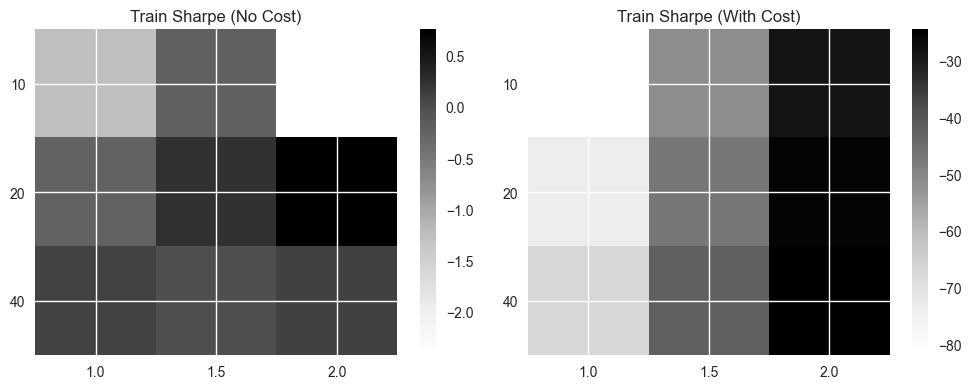

In [24]:
# Heatmap uses only the baseline (exit_bandwidth=None) configs for a clean 3×3 grid
baseline = df_results[df_results['exit_bandwidth'].isna()].copy()

pivot_nc = baseline.pivot(index='window', columns='z_entry', values='train_sharpe_no_cost')
pivot_c  = baseline.pivot(index='window', columns='z_entry', values='train_sharpe_with_cost')

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

im0 = axes[0].imshow(pivot_nc.values, aspect='auto')
axes[0].set_xticks(range(len(pivot_nc.columns)))
axes[0].set_xticklabels(pivot_nc.columns)
axes[0].set_yticks(range(len(pivot_nc.index)))
axes[0].set_yticklabels(pivot_nc.index)
axes[0].set_title('Train Sharpe (No Cost)')
plt.colorbar(im0, ax=axes[0])

im1 = axes[1].imshow(pivot_c.values, aspect='auto')
axes[1].set_xticks(range(len(pivot_c.columns)))
axes[1].set_xticklabels(pivot_c.columns)
axes[1].set_yticks(range(len(pivot_c.index)))
axes[1].set_yticklabels(pivot_c.index)
axes[1].set_title('Train Sharpe (With Cost)')
plt.colorbar(im1, ax=axes[1])

plt.tight_layout()
plt.show()

## Select candidate parameters (based on train results)

In [25]:
# Top 3 baseline configs (no hysteresis) by train Sharpe, evaluated on test
baseline = df_results[df_results['exit_bandwidth'].isna()].copy()
candidate_params = (
    baseline
    .sort_values('train_sharpe_with_cost', ascending=False)
    .head(3)
    [['window', 'z_entry', 'exit_bandwidth',
      'train_sharpe_with_cost', 'test_sharpe_no_cost', 'test_sharpe_with_cost',
      'test_trades', 'test_total_cost']]
)
candidate_params

,window,z_entry,exit_bandwidth,train_sharpe_with_cost,test_sharpe_no_cost,test_sharpe_with_cost,test_trades,test_total_cost
5,40,2.0,NaN,-24.502770,1.391463,-30.062509,3205,1.664
6,20,2.0,NaN,-25.457663,2.164488,-29.571716,3014,1.548
8,10,2.0,NaN,-28.596573,2.105581,-31.829266,2702,1.365


## Evaluate candidates on test set

In [26]:
# Test results are already computed inside grid_search — pull them out directly
test_results = df_results[df_results['exit_bandwidth'].isna()].copy()
test_results = test_results[
    ['window', 'z_entry',
     'test_sharpe_no_cost', 'test_max_dd_no_cost',
     'test_sharpe_with_cost', 'test_max_dd_with_cost', 'test_net_return']
].reset_index(drop=True)
test_results

,window,z_entry,test_sharpe_no_cost,test_max_dd_no_cost,test_sharpe_with_cost,test_max_dd_with_cost,test_net_return
0,40,2.0,1.391463,-0.125241,-30.062509,-0.796749,-1.593312
1,20,2.0,2.164488,-0.082658,-29.571716,-0.766520,-1.446789
2,10,2.0,2.105581,-0.069523,-31.829266,-0.723706,-1.284605
3,40,1.5,0.790283,-0.135239,-50.122600,-0.971345,-3.548599
4,20,1.5,0.360832,-0.132191,-55.728022,-0.977983,-3.815586
5,10,1.5,2.813175,-0.070986,-58.631849,-0.979533,-3.888958
6,40,1.0,0.423820,-0.133267,-80.566566,-0.999487,-7.574845
7,20,1.0,2.260151,-0.103278,-82.579022,-0.999619,-7.872592
8,10,1.0,1.555777,-0.107714,-89.456566,-0.999822,-8.634167


## Plot test equity for the top candidate

Best candidate: {'window': np.float64(20.0), 'z_entry': np.float64(2.0)}


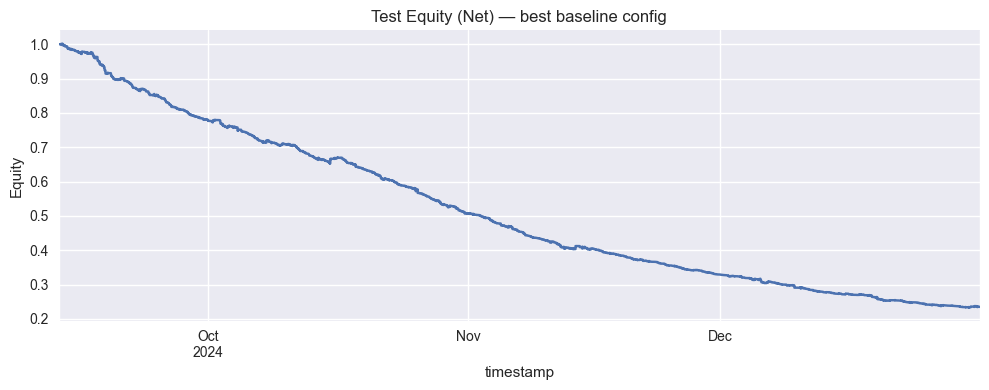

In [27]:
from src.signals import rolling_zscore_signal
from src.backtest import run_backtest_with_costs

best = test_results.sort_values('test_sharpe_with_cost', ascending=False).iloc[0]
print('Best candidate:', {k: best[k] for k in ['window', 'z_entry']})

df_test_sig = rolling_zscore_signal(df_test, window=int(best['window']), z_entry=float(best['z_entry']))
bt_test_c = run_backtest_with_costs(df_test_sig, cost_per_unit_change=COST_PER_UNIT)

fig, ax = plt.subplots(figsize=(10, 4))
bt_test_c.df['equity_curve_net'].plot(ax=ax, title='Test Equity (Net) — best baseline config')
ax.set_ylabel('Equity')
ax.grid(True)
plt.tight_layout()
plt.show()